# Part 4B: Does NVDL deliver 2x the daily NVDA return?

**Question.** Regress daily NVDL returns on daily NVDA returns (with an intercept). Report coefficients and confidence intervals. Does this show whether NVDL meets its stated objective of 2 times the daily percentage change of NVDA?

**Model.** NVDL_t = alpha + beta * NVDA_t + e_t, estimated by OLS on 147 daily observations. If the fund delivers its objective, beta should be statistically indistinguishable from 2.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = "{:,.4f}".format
# Paths are relative to part4/python_source
DATA = next(Path("../../data/raw").glob("*part 4*.xlsx"))
OUT = Path("../../output/part4"); OUT.mkdir(parents=True, exist_ok=True)

# 5 header rows, then newest-first daily total returns in decimals (0.01 = 1%)
raw = pd.read_excel(DATA, header=None, skiprows=5, names=["date", "NVDA", "NVDL"])
raw["date"] = pd.to_datetime(raw["date"])
df = raw.sort_values("date").set_index("date")   # ascending order needed before compounding
print(len(df), "trading days,", df.index.min().date(), "to", df.index.max().date())

147 trading days, 2024-02-01 to 2024-08-30


In [2]:
import statsmodels.api as sm

X = sm.add_constant(df["NVDA"])
ols = sm.OLS(df["NVDL"], X).fit()
rob = ols.get_robustcov_results(cov_type="HC3")   # robustness check on the standard errors

ci = ols.conf_int(0.05)
res = pd.DataFrame({
    "Coefficient": ols.params,
    "Std. error": ols.bse,
    "t-stat": ols.tvalues,
    "95% CI low": ci[0],
    "95% CI high": ci[1],
})
res.index = ["Intercept (alpha, daily)", "Slope (beta on NVDA)"]
res.to_csv(OUT / "4B_regression.csv")
print(f"R-squared = {ols.rsquared:.5f}, residual std. dev. = {np.sqrt(ols.scale):.5f}, n = {int(ols.nobs)}")
res

R-squared = 0.99932, residual std. dev. = 0.00196, n = 147


,Coefficient,Std. error,t-stat,95% CI low,95% CI high
"Intercept (alpha, daily)",-0.0006,0.0002,-3.7430,-0.0009,-0.0003
Slope (beta on NVDA),1.9960,0.0043,460.4122,1.9874,2.0045


In [3]:
t_beta2 = ols.t_test("NVDA = 2")
print("H0: beta = 2")
print(f"  t-stat = {float(np.squeeze(t_beta2.tvalue)):.3f}, p-value = {float(np.squeeze(t_beta2.pvalue)):.3f}")
print("HC3-robust 95% CI for beta:", np.round(rob.conf_int()[1], 4))

H0: beta = 2
  t-stat = -0.928, p-value = 0.355
HC3-robust 95% CI for beta: [1.9836 2.0084]


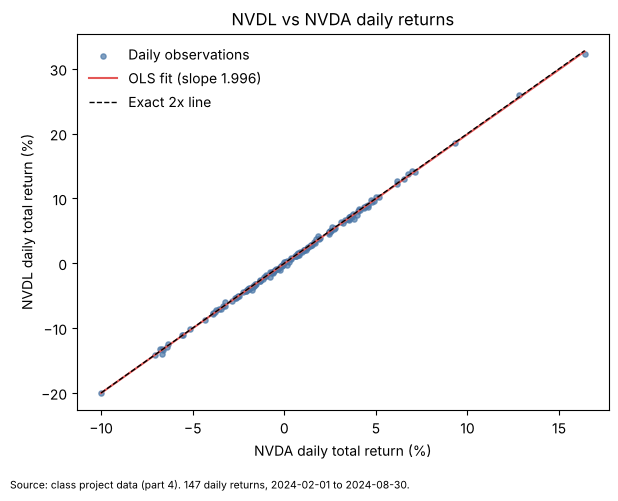

In [4]:
fig, ax = plt.subplots(figsize=(6.2, 4.8))
ax.scatter(df["NVDA"] * 100, df["NVDL"] * 100, s=14, alpha=0.7, color="#4C78A8", label="Daily observations")
xs = np.linspace(df["NVDA"].min(), df["NVDA"].max(), 50)
ax.plot(xs * 100, (ols.params["const"] + ols.params["NVDA"] * xs) * 100, color="#E45756",
        label=f"OLS fit (slope {ols.params['NVDA']:.3f})")
ax.plot(xs * 100, 2 * xs * 100, "k--", lw=1, label="Exact 2x line")
ax.set_xlabel("NVDA daily total return (%)"); ax.set_ylabel("NVDL daily total return (%)")
ax.set_title("NVDL vs NVDA daily returns"); ax.legend(frameon=False)
fig.text(0.01, -0.03, "Source: class project data (part 4). 147 daily returns, 2024-02-01 to 2024-08-30.", fontsize=7.5)
plt.tight_layout(); fig.savefig(OUT / "4B_regression.png", bbox_inches="tight"); plt.show()

## Comment

The estimated slope is about 1.996 with a 95% confidence interval of roughly [1.987, 2.005]. The interval contains 2, and the test of beta = 2 does not reject (p-value around 0.35). R-squared is about 0.999, so almost all of NVDL's daily variation is explained by NVDA's daily return. Together this shows that, on a day-by-day basis, NVDL delivers its stated objective of about twice the NVDA daily return.

What the regression does not show is the cost of delivering it. The intercept is slightly negative (about -0.06% per day) and its confidence interval excludes zero, meaning NVDL on average earns a little less than twice NVDA each day, which is analysed in 4C. The regression also says nothing about multi-day returns, because it uses daily data; 4D and 4E address that.